**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [2]:
# Завантаження файлу
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset (1).csv


In [3]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab) — *не використовується, обрано спосіб 1 (файл завантажено з комп’ютера).*

In [4]:
# Спосіб 2 не використовується: датасет завантажено способом 1.
# import kagglehub
# path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")
# print("Path to dataset files:", path)

In [5]:
# Спосіб 2 не використовується: датасет завантажено способом 1.
# df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
# df

Вивести інформацію про датасет

In [6]:
# Інформація про датасет: кількість записів, типи стовпців, ненульові значення
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


**Коментар.** Датасет містить 100 000 записів і 9 стовпців, пропусків у жодному стовпці немає (Non-Null Count = 100 000). Числові ознаки: `age`, `bmi`, `HbA1c_level` — дійсні (float64); `hypertension`, `heart_disease`, `blood_glucose_level` та цільова `diabetes` — цілі (int64). Стовпці `gender` і `smoking_history` — текстові (категоріальні), тому перед навчанням моделей їх потрібно закодувати. Ознаки `hypertension` і `heart_disease` за змістом є бінарними (0/1).

Провести дослідження категоріальних ознак

In [7]:
# Частоти категорій у стовпці gender
print("Розподіл за статтю (gender):")
gender_counts = df['gender'].value_counts()
display(pd.DataFrame({'Кількість': gender_counts,
                      'Частка, %': (gender_counts / len(df) * 100).round(2)}))

Розподіл за статтю (gender):


,Кількість,"Частка, %"
gender,,
Female,58552,58.55
Male,41430,41.43
Other,18,0.02


In [8]:
# Частоти категорій у стовпці smoking_history
print("Розподіл за історією куріння (smoking_history):")
smoking_counts = df['smoking_history'].value_counts()
display(pd.DataFrame({'Кількість': smoking_counts,
                      'Частка, %': (smoking_counts / len(df) * 100).round(2)}))

Розподіл за історією куріння (smoking_history):


,Кількість,"Частка, %"
smoking_history,,
No Info,35816,35.82
never,35095,35.10
former,9352,9.35
current,9286,9.29
not current,6447,6.45
ever,4004,4.00


In [9]:
# Повторно переглядаємо датасет після дослідження категоріальних ознак
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


**Коментар.** У `gender` переважають жінки (58,55 %) і чоловіки (41,43 %); категорія `Other` трапляється лише 18 разів (0,02 %), тому її внесок у модель мінімальний. У `smoking_history` найбільша група — `No Info` (35,82 %), тобто для третини пацієнтів історія куріння невідома; цю категорію залишаємо як окреме значення, а не вважаємо пропуском. Решта категорій: `never` (35,10 %), `former`, `current`, `not current`, `ever`.

Вивести типи даних

In [10]:
# Типи даних кожного стовпця
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [11]:
# Баланс класів цільової змінної diabetes
print(df['diabetes'].value_counts())
print("\nЧастка класів, %:")
print((df['diabetes'].value_counts(normalize=True) * 100).round(2))

diabetes
0    91500
1     8500
Name: count, dtype: int64

Частка класів, %:
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


**Висновок:** у вихідних даних 91 500 записів класу 0 (немає діабету) і лише 8 500 записів класу 1 (91,5 % проти 8,5 %). Це **виражений дисбаланс класів** (приблизно 11 : 1). Через це метрика Accuracy буде оманливою (модель, що завжди відповідає «0», вже має ≈91,5 % точності), тому основними метриками будуть recall і F1 для класу 1, а навчальну вибірку потім збалансуємо методом SMOTE.

Перевірити наявність пропущених даних


In [12]:
# Кількість пропущених значень у кожному стовпці
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [13]:
# Кількість повних дублікатів рядків
duplicates_count = df.duplicated().sum()
print(f"Кількість дублікатів: {duplicates_count}")
print(f"Частка дублікатів: {duplicates_count / len(df):.2%}")

Кількість дублікатів: 3854
Частка дублікатів: 3.85%


Видалити дублікати

In [14]:
# Видаляємо повні дублікати та оновлюємо індекси
rows_before = len(df)
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f"Рядків до видалення: {rows_before}")
print(f"Рядків після видалення: {len(df)}")
print(f"Видалено: {rows_before - len(df)}")

Рядків до видалення: 100000
Рядків після видалення: 96146
Видалено: 3854


In [15]:
# Датасет після видалення дублікатів
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
96141,Female,36.0,0,0,No Info,24.60,4.8,145,0
96142,Female,2.0,0,0,No Info,17.37,6.5,100,0
96143,Male,66.0,0,0,former,27.83,5.7,155,0
96144,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [16]:
# Баланс класів після видалення дублікатів
print(df['diabetes'].value_counts())
print("\nЧастка класів, %:")
print((df['diabetes'].value_counts(normalize=True) * 100).round(2))

diabetes
0    87664
1     8482
Name: count, dtype: int64

Частка класів, %:
diabetes
0    91.18
1     8.82
Name: proportion, dtype: float64


Побудувати гістограму для цільової змінної


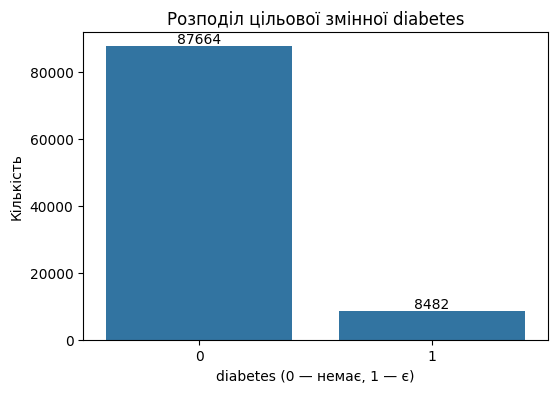

In [17]:
# Гістограма (countplot) цільової змінної
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='diabetes', data=df, color='tab:blue')
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.title('Розподіл цільової змінної diabetes')
plt.xlabel('diabetes (0 — немає, 1 — є)')
plt.ylabel('Кількість')
plt.show()

**Коментар.** Пропусків немає. Знайдено та видалено 3 854 повних дублікати (3,85 %), після чого залишилось 96 146 записів. Співвідношення класів майже не змінилося: 87 664 (91,18 %) проти 8 482 (8,82 %). Гістограма наочно підтверджує сильний дисбаланс цільової змінної.

Переглянути описові статистики **навчальної вибірки**

In [18]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [19]:
# Формуємо матрицю ознак X та цільовий вектор y
X = df.drop(columns='diabetes')
y = df['diabetes']

# Поділ 80/20 зі стратифікацією, щоб зберегти співвідношення класів
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Розмір X_train:", X_train.shape)
print("Розмір X_test:", X_test.shape)
print("\nЧастка класу 1 у train:", round(y_train.mean(), 4))
print("Частка класу 1 у test:", round(y_test.mean(), 4))

Розмір X_train: (76916, 8)
Розмір X_test: (19230, 8)

Частка класу 1 у train: 0.0882
Частка класу 1 у test: 0.0882


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [20]:
cat_cols = ['gender', 'smoking_history']

# One-hot кодування: набір стовпців формується за категоріями з train
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)

# Вирівнюємо стовпці test за train (відсутні категорії заповнюємо нулями)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Стовпці після кодування:", list(X_train.columns))
print("Розмір X_train:", X_train.shape, "| Розмір X_test:", X_test.shape)
display(X_train.head())

Стовпці після кодування: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_Male', 'gender_Other', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current']
Розмір X_train: (76916, 13) | Розмір X_test: (19230, 13)


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
76484,45.0,0,0,23.87,5.7,126,1,0,0,0,0,0,0
31572,64.0,0,0,33.03,4.0,126,0,0,0,0,1,0,0
92017,45.0,0,0,27.32,6.6,126,0,0,0,0,0,0,0
31616,44.0,1,0,28.86,4.8,80,1,0,0,0,0,0,0
94106,27.0,0,0,26.48,6.5,200,0,0,0,0,0,0,1


In [21]:
# Описові статистики навчальної вибірки
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
age,76916.0,41.760982,22.467762,0.08,24.00,43.00,59.00,80.00
hypertension,76916.0,0.078007,0.268185,0.00,0.00,0.00,0.00,1.00
heart_disease,76916.0,0.040876,0.198004,0.00,0.00,0.00,0.00,1.00
bmi,76916.0,27.313739,6.757207,10.01,23.39,27.32,29.85,95.22
HbA1c_level,76916.0,5.530527,1.072421,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,76916.0,138.114281,40.896909,80.00,100.00,140.00,159.00,300.00
gender_Male,76916.0,0.417143,0.493090,0.00,0.00,0.00,1.00,1.00
gender_Other,76916.0,0.000182,0.013490,0.00,0.00,0.00,0.00,1.00
smoking_history_current,76916.0,0.095546,0.293969,0.00,0.00,0.00,0.00,1.00
smoking_history_ever,76916.0,0.041175,0.198696,0.00,0.00,0.00,0.00,1.00


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [22]:
# Кореляція кожної ознаки X_train із цільовою змінною y_train
corr_with_target = X_train.corrwith(y_train).sort_values(key=abs, ascending=False)
print("Кореляція ознак із diabetes (лише train), відсортовано за модулем:")
display(corr_with_target.round(3).to_frame('corr з diabetes'))

Кореляція ознак із diabetes (лише train), відсортовано за модулем:


,corr з diabetes
blood_glucose_level,0.423
HbA1c_level,0.405
age,0.267
bmi,0.213
hypertension,0.199
heart_disease,0.174
smoking_history_former,0.096
gender_Male,0.041
smoking_history_never,0.026
smoking_history_ever,0.021


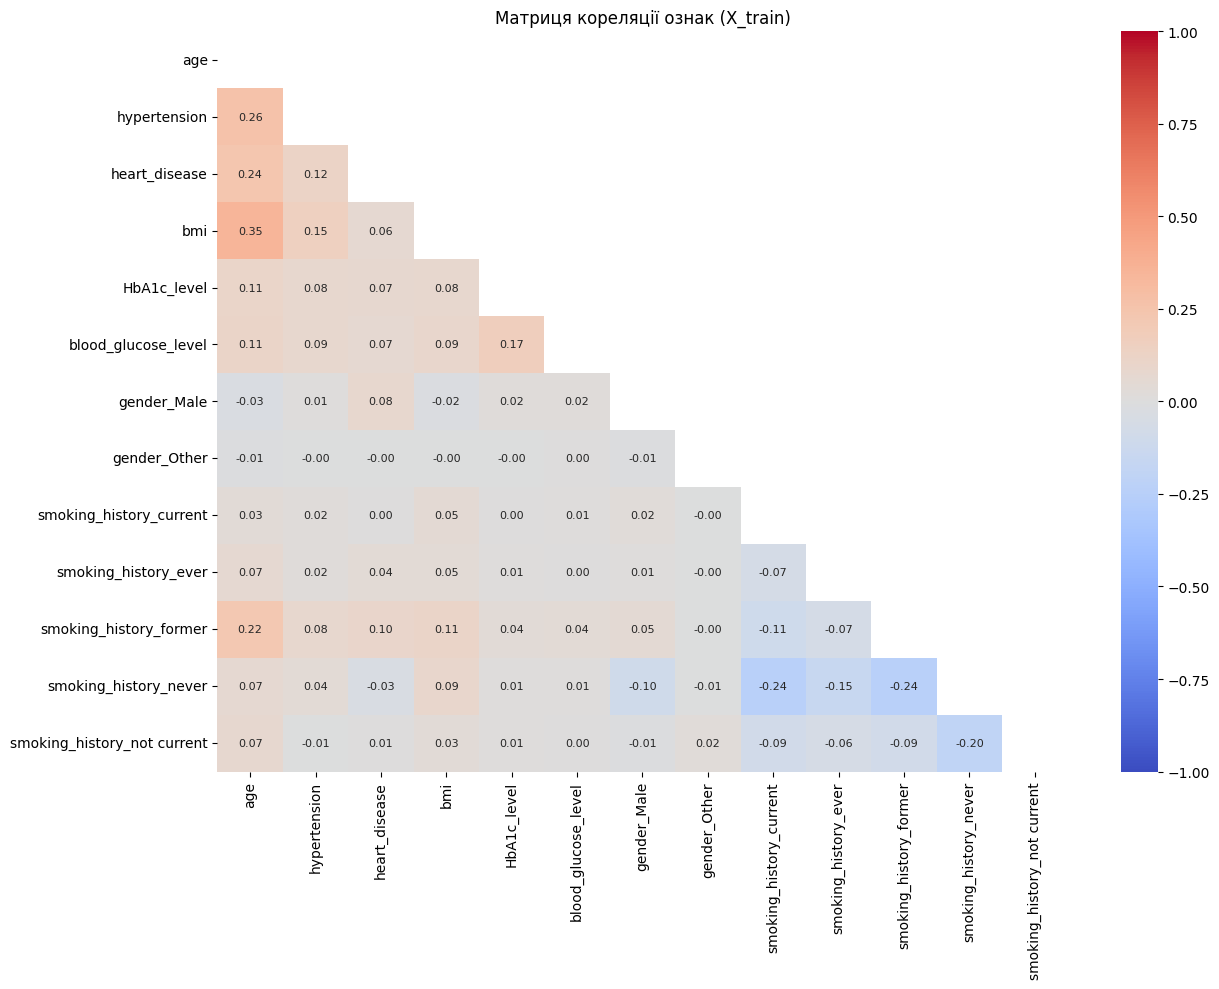

Топ-5 пар ознак за модулем кореляції:


,Ознака 1,Ознака 2,corr
3,bmi,age,0.347
0,hypertension,age,0.259
65,smoking_history_never,smoking_history_former,-0.245
63,smoking_history_never,smoking_history_current,-0.243
1,heart_disease,age,0.239


In [23]:
# Матриця кореляції ознак навчальної вибірки
corr_matrix = X_train.corr()

plt.figure(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, annot_kws={'size': 8})
plt.title('Матриця кореляції ознак (X_train)')
plt.tight_layout()
plt.show()

# Пари ознак із найбільшою кореляцією за модулем
pairs = (corr_matrix.where(~mask).stack().rename('corr')
         .reset_index().rename(columns={'level_0': 'Ознака 1', 'level_1': 'Ознака 2'}))
pairs = pairs.reindex(pairs['corr'].abs().sort_values(ascending=False).index)
print("Топ-5 пар ознак за модулем кореляції:")
display(pairs.head(5).round(3))

**Висновок:** найсильніше з цільовою змінною корелюють `blood_glucose_level` (0,42) і `HbA1c_level` (0,41), далі — `age` (0,27), `bmi` (0,21), `hypertension` (0,20) і `heart_disease` (0,17). Ознаки куріння та статі мають дуже слабкий зв'язок із `diabetes` (|r| < 0,1). Між самими ознаками сильних кореляцій немає: найбільша пара `bmi`–`age` має r = 0,35, а від'ємні кореляції між dummy-стовпцями `smoking_history` (≈ −0,24) є природним наслідком one-hot кодування. Отже, мультиколінеарності немає і **видаляти ознаки не потрібно**: навіть слабо корельовані з ціллю ознаки можуть бути корисними в поєднанні з іншими, а лінійні моделі з регуляризацією самі зменшать їхній вплив. Рішення ухвалено лише за train, тестові дані не використовувались.

Перевірити викиди **лише на навчальній вибірці**

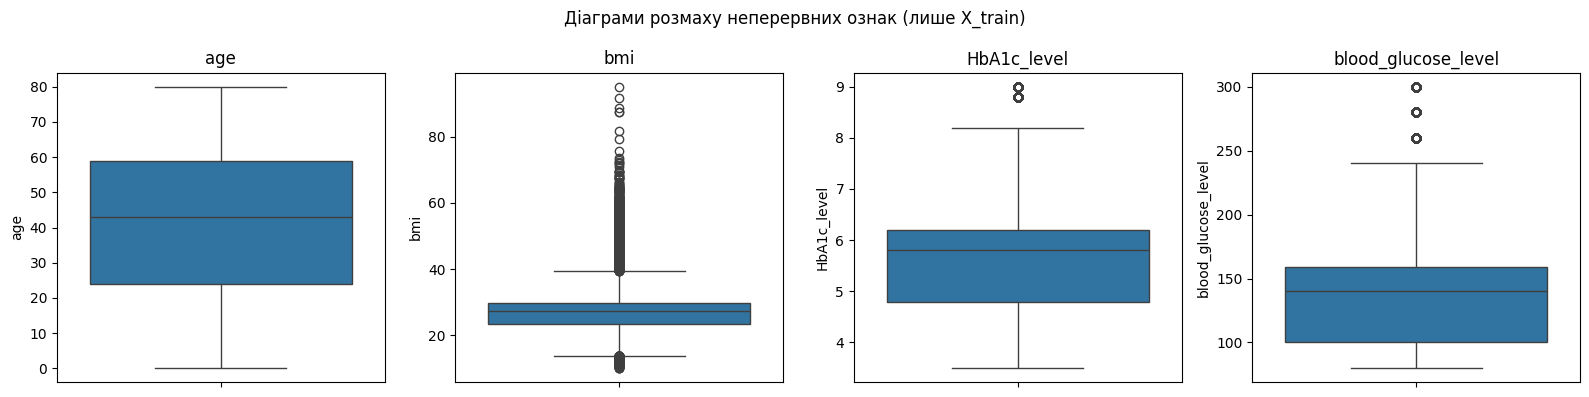

,Нижня межа,Верхня межа,Кількість викидів,"Частка, %"
age,-28.5,111.50,0,0.00
bmi,13.7,39.54,4244,5.52
HbA1c_level,2.7,8.30,1041,1.35
blood_glucose_level,11.5,247.50,1598,2.08


In [24]:
# Неперервні числові ознаки для аналізу викидів
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, continuous_cols):
    sns.boxplot(y=X_train[col], ax=ax, color='tab:blue')
    ax.set_title(col)
plt.suptitle('Діаграми розмаху неперервних ознак (лише X_train)')
plt.tight_layout()
plt.show()

# Кількість потенційних викидів за правилом 1.5*IQR (межі — лише за train)
q1 = X_train[continuous_cols].quantile(0.25)
q3 = X_train[continuous_cols].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = ((X_train[continuous_cols] < lower) | (X_train[continuous_cols] > upper)).sum()
display(pd.DataFrame({'Нижня межа': lower, 'Верхня межа': upper,
                      'Кількість викидів': outliers,
                      'Частка, %': (outliers / len(X_train) * 100).round(2)}).round(2))

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

За правилом 1,5·IQR (межі обчислено лише за train) найбільше потенційних викидів у `bmi` — 4 244 (5,52 %), далі `blood_glucose_level` — 1 598 (2,08 %) і `HbA1c_level` — 1 041 (1,35 %); в `age` викидів немає. Високі значення глюкози (понад 247,5) та HbA1c (понад 8,3) — це якраз типові ознаки діабету, тож їх видалення прибрало б із навчання найінформативніші приклади класу 1.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [25]:
# НЕОБОВ'ЯЗКОВО (у цій роботі не запускаємо — викиди не видаляємо).
# Приклад: межі IQR для bmi обчислюємо тільки на X_train,
# рядки видаляємо синхронно з X_train та y_train, X_test і y_test не змінюємо.
#
# q1_bmi = X_train['bmi'].quantile(0.25)
# q3_bmi = X_train['bmi'].quantile(0.75)
# iqr_bmi = q3_bmi - q1_bmi
# low_bmi, high_bmi = q1_bmi - 1.5 * iqr_bmi, q3_bmi + 1.5 * iqr_bmi
# keep_mask = X_train['bmi'].between(low_bmi, high_bmi)
# X_train, y_train = X_train[keep_mask], y_train[keep_mask]

Перевірити асиметрію розподілів ознак **на train**

,Асиметрія (skew)
bmi,1.005
blood_glucose_level,0.831
HbA1c_level,-0.056
age,-0.061


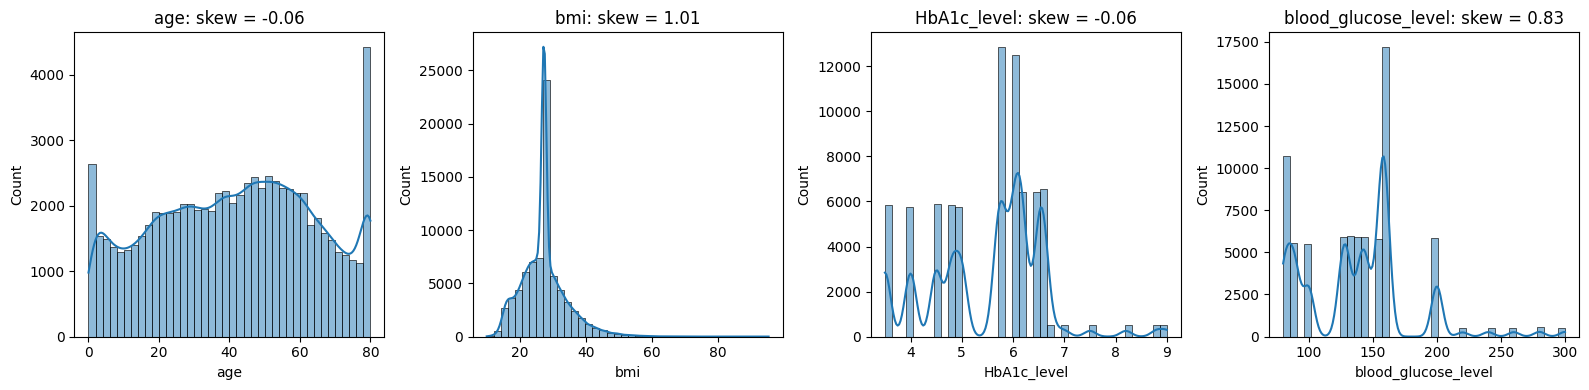

In [26]:
# Коефіцієнти асиметрії неперервних ознак (лише train)
skewness = X_train[continuous_cols].skew().sort_values(ascending=False)
display(skewness.round(3).to_frame('Асиметрія (skew)'))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, continuous_cols):
    sns.histplot(X_train[col], bins=40, kde=True, ax=ax, color='tab:blue')
    ax.set_title(f'{col}: skew = {X_train[col].skew():.2f}')
plt.tight_layout()
plt.show()

In [27]:
# Перевірка пропусків окремо в train і test
print("Пропуски в X_train:", X_train.isnull().sum().sum())
print("Пропуски в X_test:", X_test.isnull().sum().sum())
print("Пропуски в y_train:", y_train.isnull().sum(), "| y_test:", y_test.isnull().sum())

Пропуски в X_train: 0
Пропуски в X_test: 0
Пропуски в y_train: 0 | y_test: 0


**Проміжний висновок:** цільова змінна сильно незбалансована (≈ 8,8 % позитивних випадків у train і test завдяки `stratify=y`). На train найбільший зв'язок із діабетом мають рівень глюкози та HbA1c, мультиколінеарності між ознаками немає, тому всі ознаки залишено. Викиди є в `bmi`, `blood_glucose_level` та `HbA1c_level`, але вони правдоподібні й клінічно значущі, тому не видаляються. Найбільшу правосторонню асиметрію має `bmi` (1,01) та `blood_glucose_level` (0,83); `age` і `HbA1c_level` майже симетричні. Пропусків у train і test немає. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [28]:
# Масштабування: параметри (середнє, std) обчислюємо лише за train
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Середні X_train_scaled (перші 5):", np.round(X_train_scaled.mean(axis=0)[:5], 3))
print("Std X_train_scaled (перші 5):", np.round(X_train_scaled.std(axis=0)[:5], 3))

Середні X_train_scaled (перші 5): [-0.  0.  0. -0. -0.]
Std X_train_scaled (перші 5): [1. 1. 1. 1. 1.]


Балансуємо лише навчальну вибірку за допомогою SMOTE

In [29]:
# SMOTE застосовуємо тільки до масштабованої навчальної вибірки
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print("Кількість класів до SMOTE:")
print(y_train.value_counts())
print("\nКількість класів після SMOTE:")
print(pd.Series(y_train_res).value_counts())
print("\nТестова вибірка не змінюється:", y_test.value_counts().to_dict())

Кількість класів до SMOTE:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Кількість класів після SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64

Тестова вибірка не змінюється: {0: 17534, 1: 1696}


Оголошуємо моделі

In [30]:
# Словник моделей для порівняння
models = {
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=42),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42, cache_size=1000),
}
for name, model in models.items():
    print(f"{name}: {model}")

LogisticRegression: LogisticRegression(max_iter=1000, random_state=42)
RidgeClassifier: RidgeClassifier(random_state=42)
SGDClassifier: SGDClassifier(random_state=42)
SVC: SVC(cache_size=1000, random_state=42)


Навчити моделі, вивести матриці плутанини, класифікаційний звіт


Модель: LogisticRegression
              precision    recall  f1-score   support

           0      0.987     0.886     0.934     17534
           1      0.426     0.879     0.574      1696

    accuracy                          0.885     19230
   macro avg      0.707     0.882     0.754     19230
weighted avg      0.938     0.885     0.902     19230



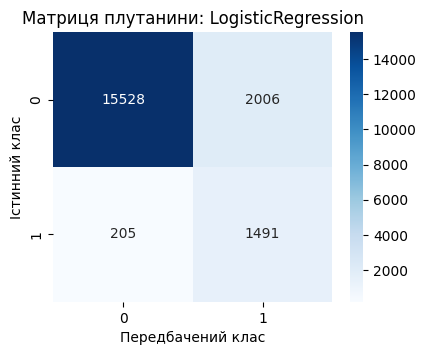

Модель: RidgeClassifier
              precision    recall  f1-score   support

           0      0.987     0.889     0.935     17534
           1      0.433     0.875     0.579      1696

    accuracy                          0.888     19230
   macro avg      0.710     0.882     0.757     19230
weighted avg      0.938     0.888     0.904     19230



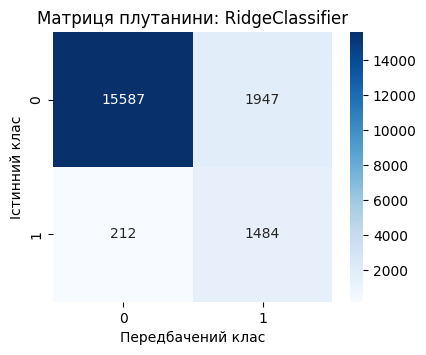

Модель: SGDClassifier
              precision    recall  f1-score   support

           0      0.990     0.855     0.917     17534
           1      0.377     0.910     0.534      1696

    accuracy                          0.860     19230
   macro avg      0.684     0.882     0.725     19230
weighted avg      0.936     0.860     0.884     19230



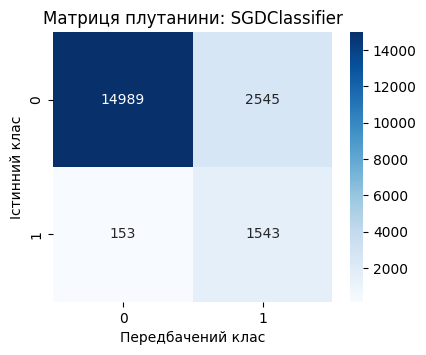

Модель: SVC
              precision    recall  f1-score   support

           0      0.990     0.881     0.932     17534
           1      0.425     0.909     0.579      1696

    accuracy                          0.883     19230
   macro avg      0.707     0.895     0.756     19230
weighted avg      0.940     0.883     0.901     19230



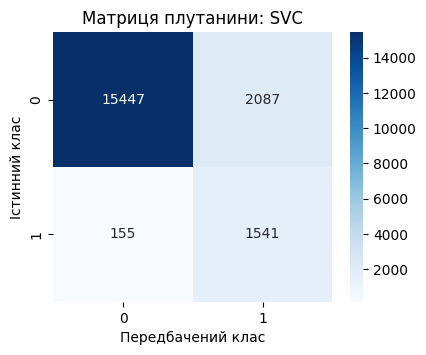

Зведена таблиця метрик базових моделей (test):


,Accuracy,Precision (1),Recall (1),F1 (1)
Модель,,,,
LogisticRegression,0.885,0.426,0.879,0.574
RidgeClassifier,0.888,0.433,0.875,0.579
SGDClassifier,0.860,0.377,0.910,0.534
SVC,0.883,0.425,0.909,0.579


In [31]:
from sklearn.metrics import f1_score, recall_score, precision_score, accuracy_score

base_results = []
base_predictions = {}

for name, model in models.items():
    # Навчання на збалансованій навчальній вибірці
    model.fit(X_train_res, y_train_res)
    # Прогноз на масштабованій тестовій вибірці
    y_pred = model.predict(X_test_scaled)
    base_predictions[name] = y_pred

    print("=" * 60)
    print(f"Модель: {name}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, digits=3))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['0', '1'], yticklabels=['0', '1'])
    plt.title(f'Матриця плутанини: {name}')
    plt.xlabel('Передбачений клас')
    plt.ylabel('Істинний клас')
    plt.show()

    base_results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (1)': precision_score(y_test, y_pred),
        'Recall (1)': recall_score(y_test, y_pred),
        'F1 (1)': f1_score(y_test, y_pred),
    })

base_results_df = pd.DataFrame(base_results).set_index('Модель')
print("Зведена таблиця метрик базових моделей (test):")
display(base_results_df.round(3))

**Висновок щодо базових моделей.** Після балансування SMOTE усі чотири моделі добре знаходять хворих: recall для класу 1 становить 0,88–0,91 (найвищий у SGDClassifier — 0,910 та SVC — 0,909). Водночас precision для класу 1 низька (0,38–0,43): моделі дають багато хибнопозитивних прогнозів, тобто частина здорових пацієнтів позначається як хворі. F1 для класу 1 приблизно однаковий — 0,57–0,58 у LogisticRegression, RidgeClassifier та SVC і 0,54 у SGDClassifier. Accuracy (0,86–0,89) нижча за «наївні» 91 %, але це очікувано: модель свідомо жертвує точністю на класі 0 заради виявлення діабету. У медичній задачі пропустити хворого гірше, ніж зайвий раз направити на обстеження, тому високий recall тут важливіший.

Оптимізувати гіперпараметри


In [32]:
# Сітки гіперпараметрів для кожної моделі (префікс model__ — крок Pipeline)
param_grids = {
    'LogisticRegression': {
        'model__C': [0.01, 0.1, 1, 10, 100],
        'model__solver': ['lbfgs', 'liblinear', 'saga'],
    },
    'RidgeClassifier': {
        'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
        'model__fit_intercept': [True, False],
    },
    'SGDClassifier': {
        'model__loss': ['hinge', 'log_loss', 'modified_huber'],
        'model__penalty': ['l2', 'l1', 'elasticnet'],
        'model__alpha': [0.0001, 0.001, 0.01],
    },
    'SVC': {
        'model__C': [0.1, 1, 10],
        'model__kernel': ['linear', 'rbf', 'poly'],
    },
}
for name, grid in param_grids.items():
    n_comb = int(np.prod([len(v) for v in grid.values()]))
    print(f"{name}: {n_comb} комбінацій")

LogisticRegression: 15 комбінацій
RidgeClassifier: 14 комбінацій
SGDClassifier: 27 комбінацій
SVC: 9 комбінацій


Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [33]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

LogisticRegression: оптимальні параметри {'model__C': 0.01, 'model__solver': 'saga'}
Середній F1 на кросвалідації: 0.642
              precision    recall  f1-score   support

           0      0.987     0.886     0.934     17534
           1      0.427     0.880     0.575      1696

    accuracy                          0.885     19230
   macro avg      0.707     0.883     0.754     19230
weighted avg      0.938     0.885     0.902     19230



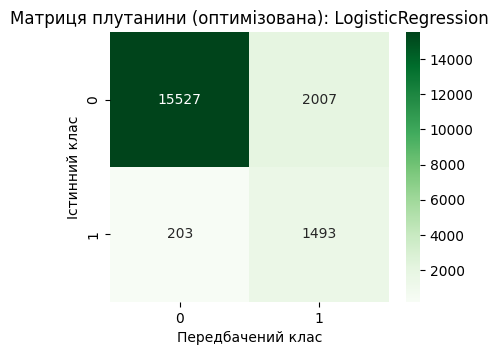

RidgeClassifier: оптимальні параметри {'model__alpha': 100, 'model__fit_intercept': True}
Середній F1 на кросвалідації: 0.640
              precision    recall  f1-score   support

           0      0.987     0.889     0.935     17534
           1      0.433     0.875     0.579      1696

    accuracy                          0.888     19230
   macro avg      0.710     0.882     0.757     19230
weighted avg      0.938     0.888     0.904     19230



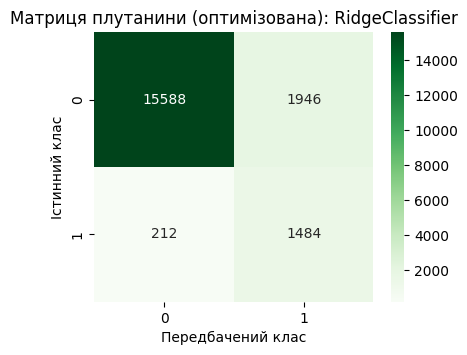

SGDClassifier: оптимальні параметри {'model__alpha': 0.001, 'model__loss': 'log_loss', 'model__penalty': 'l2'}
Середній F1 на кросвалідації: 0.618
              precision    recall  f1-score   support

           0      0.987     0.883     0.932     17534
           1      0.422     0.882     0.571      1696

    accuracy                          0.883     19230
   macro avg      0.705     0.883     0.752     19230
weighted avg      0.937     0.883     0.900     19230



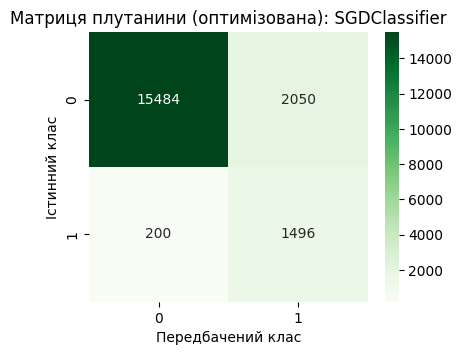

SVC: оптимальні параметри {'model__C': 0.1, 'model__kernel': 'poly'}
Середній F1 на кросвалідації: 0.694
              precision    recall  f1-score   support

           0      0.983     0.927     0.954     17534
           1      0.523     0.831     0.642      1696

    accuracy                          0.918     19230
   macro avg      0.753     0.879     0.798     19230
weighted avg      0.942     0.918     0.926     19230



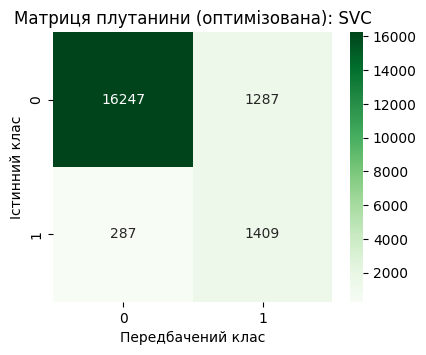

Хід пошуку HalvingGridSearchCV:


,Ітерацій,Ресурси (рядків),Кандидатів,CV F1
Модель,,,,
LogisticRegression,3,"[300, 900, 2700]","[15, 5, 2]",0.642
RidgeClassifier,3,"[300, 900, 2700]","[14, 5, 2]",0.640
SGDClassifier,4,"[300, 900, 2700, 8100]","[27, 9, 3, 1]",0.618
SVC,3,"[300, 900, 2700]","[9, 3, 1]",0.694


In [34]:
best_models = {}
best_scores = {}
search_info = []

# Для SVC пошук виконуємо на стратифікованій підвибірці train (20 000 рядків):
# складність SVC зростає приблизно квадратично з кількістю об'єктів,
# а фінальне перенавчання (refit) на всій вибірці після SMOTE (~140 тис.) дуже довге.
X_train_svc, _, y_train_svc, _ = train_test_split(
    X_train, y_train, train_size=20000, random_state=42, stratify=y_train
)

for name, model in models.items():
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model),
    ])
    search = HalvingGridSearchCV(
        pipe, param_grids[name], cv=3, scoring='f1',
        factor=3, min_resources=300, random_state=42, n_jobs=-1
    )
    X_fit, y_fit = (X_train_svc, y_train_svc) if name == 'SVC' else (X_train, y_train)
    search.fit(X_fit, y_fit)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_
    search_info.append({'Модель': name,
                        'Ітерацій': search.n_iterations_,
                        'Ресурси (рядків)': search.n_resources_,
                        'Кандидатів': search.n_candidates_,
                        'CV F1': search.best_score_})

    y_pred_best = search.best_estimator_.predict(X_test)
    print("=" * 60)
    print(f"{name}: оптимальні параметри {search.best_params_}")
    print(f"Середній F1 на кросвалідації: {search.best_score_:.3f}")
    print("=" * 60)
    print(classification_report(y_test, y_pred_best, digits=3))

    cm = confusion_matrix(y_test, y_pred_best)
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
                xticklabels=['0', '1'], yticklabels=['0', '1'])
    plt.title(f'Матриця плутанини (оптимізована): {name}')
    plt.xlabel('Передбачений клас')
    plt.ylabel('Істинний клас')
    plt.show()

print("Хід пошуку HalvingGridSearchCV:")
display(pd.DataFrame(search_info).set_index('Модель').round(3))

**Висновок щодо підбору гіперпараметрів.** HalvingGridSearchCV спочатку оцінює всі комбінації на 300 рядках, а потім залишає приблизно третину найкращих і збільшує обсяг даних утричі (300 → 900 → 2 700 → 8 100). Оптимальні параметри: LogisticRegression — `C=0.01, solver='saga'`; RidgeClassifier — `alpha=100`; SGDClassifier — `loss='log_loss', penalty='l2', alpha=0.001`; SVC — `C=0.1, kernel='poly'`. Для лінійних моделей виграли сильніші значення регуляризації, проте якість на тесті майже не змінилася (F1 класу 1 ≈ 0,57–0,58), тобто лінійні моделі вже досягли своєї межі. Найбільше покращення дав SVC з поліноміальним ядром: F1 класу 1 зріс з 0,579 до 0,642, precision — з 0,425 до 0,523, accuracy — до 0,918, хоча recall зменшився до 0,831. Значення F1 на кросвалідації (0,62–0,69) вищі за тестові, бо фінальні ітерації пошуку проходили на невеликих підвибірках і в згинах після SMOTE; тому їх використовуємо для порівняння моделей між собою, а не як точну оцінку якості.

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [35]:
# Найкраща модель — за середнім F1 на кросвалідації (тест не використовуємо)
cv_table = pd.Series(best_scores, name='CV F1').sort_values(ascending=False)
display(cv_table.round(3).to_frame())

best_name = cv_table.idxmax()
best_model = best_models[best_name]
print(f"Найкраща модель: {best_name}")
print(f"Середній F1 на кросвалідації: {best_scores[best_name]:.3f}")

,CV F1
SVC,0.694
LogisticRegression,0.642
RidgeClassifier,0.640
SGDClassifier,0.618


Найкраща модель: SVC
Середній F1 на кросвалідації: 0.694


In [36]:
# 10 випадкових записів тестової вибірки
sample_idx = X_test.sample(n=10, random_state=42).index
sample_pred = best_model.predict(X_test.loc[sample_idx])

comparison = pd.DataFrame({
    'Індекс': sample_idx,
    'Істинний клас': y_test.loc[sample_idx].values,
    'Передбачений клас': sample_pred,
})
comparison['Збіг'] = np.where(comparison['Істинний клас'] == comparison['Передбачений клас'], 'так', 'ні')
print(f"Прогнози моделі {best_name} для 10 випадкових тестових записів:")
display(comparison)
print(f"Правильних прогнозів: {(comparison['Збіг'] == 'так').sum()} з 10")

Прогнози моделі SVC для 10 випадкових тестових записів:


,Індекс,Істинний клас,Передбачений клас,Збіг
0,35493,0,0,так
1,29438,0,0,так
2,29287,0,0,так
3,11752,0,0,так
4,95450,0,0,так
5,26415,0,0,так
6,51899,0,0,так
7,67326,0,0,так
8,8881,0,0,так
9,36474,0,0,так


Правильних прогнозів: 10 з 10


**Підсумкові висновки:**

1. **Дисбаланс, кореляції та викиди.** У даних спостерігався сильний дисбаланс класів: після видалення 3 854 дублікатів 91,18 % записів належать до класу 0 і лише 8,82 % — до класу 1. На навчальній вибірці найсильніше з `diabetes` корелюють `blood_glucose_level` (0,42) і `HbA1c_level` (0,41), а між ознаками сильних кореляцій немає (максимум 0,35 для `bmi`–`age`), тому всі ознаки було залишено. Викиди за 1,5·IQR знайдено в `bmi` (5,5 %), `blood_glucose_level` (2,1 %) та `HbA1c_level` (1,4 %), але їх не видаляли, бо це клінічно правдоподібні значення.

2. **Найкращі моделі за F1 та recall.** Серед базових моделей найвищий recall для класу 1 мали SGDClassifier (0,910) і SVC (0,909), найвищий F1 — RidgeClassifier та SVC (0,579). Після оптимізації найкращою за середнім F1 на кросвалідації виявилась модель **SVC** (CV F1 = 0,694); на тесті вона дала F1 = 0,642, recall = 0,831 і accuracy = 0,918 для класу 1. На 10 випадкових тестових записах SVC зробила 10 правильних прогнозів із 10 (усі вибрані записи належали до класу 0, що відображає дисбаланс тестової вибірки).

3. **Оптимальні гіперпараметри та помилки.** LogisticRegression: `C=0.01, solver='saga'`; RidgeClassifier: `alpha=100`; SGDClassifier: `loss='log_loss', penalty='l2', alpha=0.001`; SVC: `C=0.1, kernel='poly'`. Матриці плутанини показують, що основний тип помилок усіх моделей — **хибнопозитивні** прогнози (здорових пацієнтів віднесено до класу 1), через що precision для класу 1 становить лише 0,38–0,52. Хибнонегативних помилок значно менше, що для медичної задачі є бажаним.

4. **Навіщо відкладати тест і робити масштабування й SMOTE тільки на train.** Тестова вибірка імітує нові, ще не бачені дані, тому вона не повинна впливати ні на вибір ознак, ні на межі викидів, ні на параметри масштабування — інакше виникає витік даних (data leakage) і завищена оцінка якості. SMOTE створює штучні об'єкти, тому балансувати можна лише train: тест має зберегти реальне співвідношення класів, щоб метрики відповідали реальним умовам застосування моделі. З тієї ж причини в HalvingGridSearchCV масштабування і SMOTE виконувались усередині Pipeline в кожному навчальному згині.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

In [39]:
!pip install catboost -q

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Градієнтні бустинги навчаємо на тій самій збалансованій (SMOTE) навчальній вибірці
boosting_models = {
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                             eval_metric='logloss', random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(n_estimators=300, learning_rate=0.1,
                               random_state=42, verbose=-1),
    'CatBoost': CatBoostClassifier(iterations=300, depth=6, learning_rate=0.1,
                                   random_state=42, verbose=0),
}

Модель: XGBoost
              precision    recall  f1-score   support

           0      0.972     0.995     0.984     17534
           1      0.937     0.706     0.806      1696

    accuracy                          0.970     19230
   macro avg      0.955     0.851     0.895     19230
weighted avg      0.969     0.970     0.968     19230



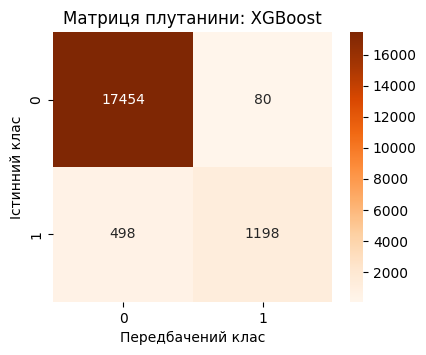

Модель: LightGBM
              precision    recall  f1-score   support

           0      0.972     0.995     0.983     17534
           1      0.936     0.701     0.802      1696

    accuracy                          0.969     19230
   macro avg      0.954     0.848     0.893     19230
weighted avg      0.969     0.969     0.967     19230



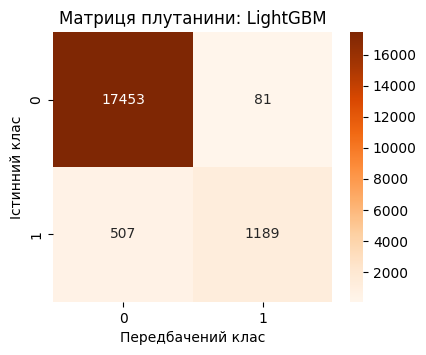

Модель: CatBoost
              precision    recall  f1-score   support

           0      0.972     0.997     0.984     17534
           1      0.951     0.702     0.808      1696

    accuracy                          0.971     19230
   macro avg      0.962     0.849     0.896     19230
weighted avg      0.970     0.971     0.968     19230



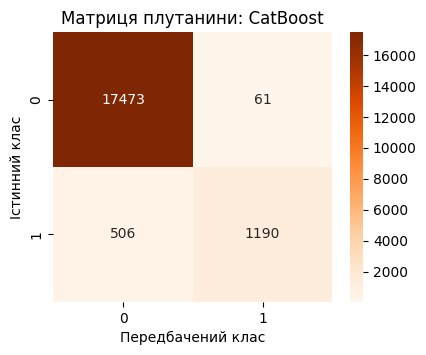

In [40]:
boost_results = []

for name, model in boosting_models.items():
    model.fit(X_train_res, y_train_res)
    y_pred = model.predict(X_test_scaled)

    print("=" * 60)
    print(f"Модель: {name}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, digits=3))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
                xticklabels=['0', '1'], yticklabels=['0', '1'])
    plt.title(f'Матриця плутанини: {name}')
    plt.xlabel('Передбачений клас')
    plt.ylabel('Істинний клас')
    plt.show()

    boost_results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (1)': precision_score(y_test, y_pred),
        'Recall (1)': recall_score(y_test, y_pred),
        'F1 (1)': f1_score(y_test, y_pred),
    })

,Accuracy,Precision (1),Recall (1),F1 (1)
Модель,,,,
CatBoost,0.971,0.951,0.702,0.808
XGBoost,0.970,0.937,0.706,0.806
LightGBM,0.969,0.936,0.701,0.802
RidgeClassifier,0.888,0.433,0.875,0.579
SVC,0.883,0.425,0.909,0.579
LogisticRegression,0.885,0.426,0.879,0.574
SGDClassifier,0.860,0.377,0.910,0.534


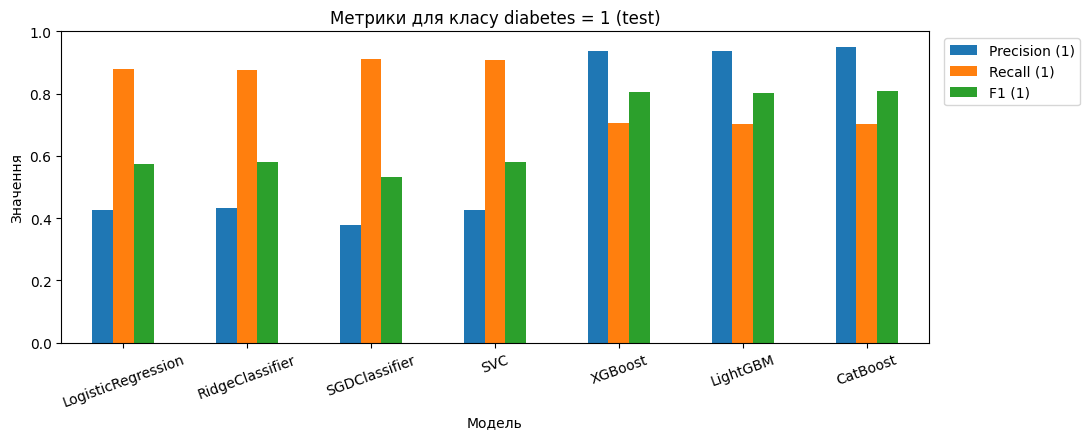

In [41]:
# Порівняння бустингів із базовими лінійними моделями та SVC (тестова вибірка)
all_results = pd.concat([base_results_df, pd.DataFrame(boost_results).set_index('Модель')])
display(all_results.round(3).sort_values('F1 (1)', ascending=False))

all_results[['Precision (1)', 'Recall (1)', 'F1 (1)']].plot(kind='bar', figsize=(11, 4.5))
plt.title('Метрики для класу diabetes = 1 (test)')
plt.ylabel('Значення')
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Висновок до додаткового завдання.** Градієнтні бустинги значно перевершили лінійні моделі та SVC: accuracy ≈ 0,97, F1 для класу 1 — 0,808 (CatBoost), 0,806 (XGBoost) і 0,801 (LightGBM). Найбільша зміна — у precision для класу 1 (0,93–0,96 проти 0,38–0,52 у лінійних моделей): бустинги майже не дають хибнопозитивних прогнозів, бо деревоподібні моделі вловлюють нелінійні пороги (наприклад, HbA1c ≥ 6,5 чи глюкоза ≥ 200), які є діагностичними критеріями діабету. Ціною цього є нижчий recall — близько 0,70, тобто бустинги пропускають приблизно 30 % хворих, тоді як лінійні моделі пропускають лише 9–12 %. Отже, за загальним балансом (F1) найкращий CatBoost, але якщо пріоритетом є не пропустити хворого, варто або зменшити поріг класифікації бустингу (наприклад, з 0,5 до 0,3), або обирати модель з вищим recall.